## LAB1 : Introduction to Natural Language Processing (NLP)
### Analyse de sentiments des avis clients Yelp Reviews


**Problématique :** Peut-on prédire la note attribuée par un client à un établissement à partir du texte de son avis ?

 ### 1-Importation des bibliothèques

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
import nltk

print("Bibliothèques importées avec succès.")

Bibliothèques importées avec succès.


### 2 — Installation et téléchargement des ressources NLP

In [3]:
import nltk
nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

print("Les ressources NLTK sont prêtes.")
for p in ["punkt", "punkt_tab", "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(p, quiet=True)

Les ressources NLTK sont prêtes.


### 3 — Chargement du dataset 

In [4]:
import pandas as pd

df = pd.read_csv("yelp Restaurant Reviews.csv")

print("Dataset chargé avec succès !")
print("Dimensions :", df.shape)

df.head()

Dataset chargé avec succès !
Dimensions : (19896, 4)


,Yelp URL,Rating,Date,Review Text
0,https://www.yelp.com/biz/sidney-dairy-barn-sidney,5,1/22/2022,All I can say is they have very good ice cream...
1,https://www.yelp.com/biz/sidney-dairy-barn-sidney,4,6/26/2022,Nice little local place for ice cream.My favor...
2,https://www.yelp.com/biz/sidney-dairy-barn-sidney,5,8/7/2021,A delicious treat on a hot day! Staff was very...
3,https://www.yelp.com/biz/sidney-dairy-barn-sidney,4,7/28/2016,This was great service and a fun crew! I got t...
4,https://www.yelp.com/biz/sidney-dairy-barn-sidney,5,6/23/2015,This is one of my favorite places to get ice c...


## 1. Exploration et compréhension du dataset

Cette étape permet d'examiner la structure du dataset, de comprendre les variables disponibles et d'étudier la distribution des notes attribuées par les clients. Cette analyse nous aide à mieux préparer les données pour les étapes suivantes du traitement automatique du langage naturel.

In [5]:
print("Noms des colonnes :")
print(df.columns.tolist())

print("\nInformations générales :")
df.info()

print("\nValeurs manquantes :")
print(df.isnull().sum())

Noms des colonnes :
['Yelp URL', 'Rating', 'Date', 'Review Text']

Informations générales :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19896 entries, 0 to 19895
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Yelp URL     19896 non-null  object
 1   Rating       19896 non-null  int64 
 2   Date         19896 non-null  object
 3   Review Text  19896 non-null  object
dtypes: int64(1), object(3)
memory usage: 621.9+ KB

Valeurs manquantes :
Yelp URL       0
Rating         0
Date           0
Review Text    0
dtype: int64


1 — Statistiques descriptives

In [6]:
# Afficher les dimensions du dataset
print("Nombre d'avis :", df.shape[0])
print("Nombre de colonnes :", df.shape[1])

# Afficher les types de données
print("\nTypes des colonnes :")
print(df.dtypes)

# Afficher les statistiques des notes
print("\nStatistiques des notes :")
print(df["Rating"].describe())

Nombre d'avis : 19896
Nombre de colonnes : 4

Types des colonnes :
Yelp URL       object
Rating          int64
Date           object
Review Text    object
dtype: object

Statistiques des notes :
count    19896.000000
mean         4.130830
std          1.200746
min          1.000000
25%          4.000000
50%          5.000000
75%          5.000000
max          5.000000
Name: Rating, dtype: float64


— Distribution des notes

Nombre d'avis par note :
Rating
1     1217
2     1280
3     2069
4     4447
5    10883
Name: count, dtype: int64


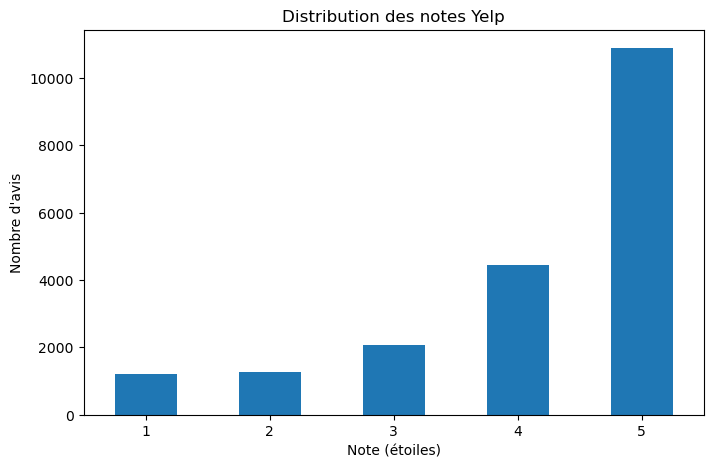

In [7]:
import matplotlib.pyplot as plt

rating_counts = df["Rating"].value_counts().sort_index()

print("Nombre d'avis par note :")
print(rating_counts)

plt.figure(figsize=(8, 5))
rating_counts.plot(kind="bar")
plt.title("Distribution des notes Yelp")
plt.xlabel("Note (étoiles)")
plt.ylabel("Nombre d'avis")
plt.xticks(rotation=0)
plt.show()

Cellule 3 — Longueur des avis

count    19896.000000
mean        91.383544
std         79.997138
min          1.000000
25%         38.000000
50%         68.000000
75%        118.000000
max        949.000000
Name: Word Count, dtype: float64


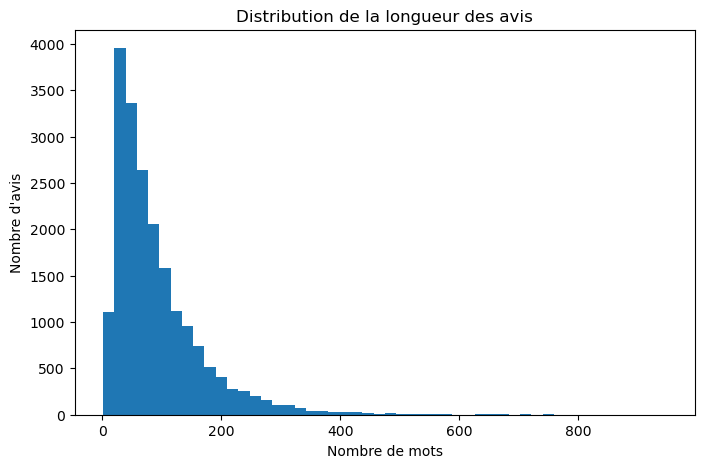

In [8]:
# Calculer le nombre de mots dans chaque avis
df["Word Count"] = df["Review Text"].apply(
    lambda text: len(str(text).split())
)

print(df["Word Count"].describe())

plt.figure(figsize=(8, 5))
plt.hist(df["Word Count"], bins=50)
plt.title("Distribution de la longueur des avis")
plt.xlabel("Nombre de mots")
plt.ylabel("Nombre d'avis")
plt.show()

In [9]:
pd.set_option("display.max_colwidth", 150)

df[["Rating", "Review Text"]].sample(
    5, random_state=42
)

,Rating,Review Text
9507,5,Tonight was my first time coming here and it was great! The people working the counter were very friendly and very willing to help you figure out ...
1512,5,All I can say about this place is... you must try a chocolate covered strawberry! They are huge and juicy and delicious! The baked goods look amaz...
17433,4,"This place is near Fremont street. Had to pay for parking out front, but it was only $1. We ordered the French Toast donut and two creme brulee do..."
8477,2,"While I am glad I can say I've tried Sprinkles Cupcakes, I'm disappointed because I wouldn't recommend them to anyone. If I wanted a dry, tasteles..."
14457,4,I lived in New York City nearly 20 years and the New York Milk Bar's in Manhattan and Brooklyn were always my favorite. The cookies in particular ...


— Créer les catégories de sentiment

## 2. Création des catégories de sentiment

Dans cette étape, les notes numériques sont transformées en trois catégories : négatif, neutre et positif. Les notes de 1 et 2 étoiles sont considérées comme négatives, la note de 3 étoiles comme neutre, et les notes de 4 et 5 étoiles comme positives.

Cette transformation permet de réaliser une tâche de classification de sentiment à partir du texte des avis.

In [10]:
# Transformer les notes en catégories de sentiment
def classify_sentiment(rating):
    if rating <= 2:
        return "negative"
    elif rating == 3:
        return "neutral"
    else:
        return "positive"

df["Sentiment"] = df["Rating"].apply(classify_sentiment)

# Afficher quelques exemples
df[["Rating", "Sentiment", "Review Text"]].head(15)

,Rating,Sentiment,Review Text
0,5,positive,All I can say is they have very good ice cream I would for sure recommend their cookies and creme ice cream it is very good
1,4,positive,Nice little local place for ice cream.My favorite is their pumpkin shake ( Fall season special).( My Sweetness tolerance is low) Their LARGE SIZE ...
2,5,positive,A delicious treat on a hot day! Staff was very friendly and helpful-- gave us a sample and let us order a little earlier than open.
3,4,positive,This was great service and a fun crew! I got the banana cream pie with chocolate ice cream. I loved the flavor of this. It had freshly cut bananas...
4,5,positive,"This is one of my favorite places to get ice cream in the CU area. It's a bit of drive, but it is worth it. It's about 10 minutes from the far sid..."
5,5,positive,"I've been coming to this ice cream stand since I was a little girl back in the 1970's. (Yes, it's been here for that long! Just not under the same..."
6,1,negative,"The soft-serve is way too sweet and has a strange Splenda-like aftertaste. The flavors tasted very artificial, and I ended up with a stomach ache ..."
7,5,positive,My husband and I stopped here on the way back to Monticello from Westville (Go Sages!). He had a chocolate shake and I had a cookie dough tornado....
8,5,positive,"Little piece of heaven, the best ice cream shop near Champaign Urbana. Decent prices, superb taste; What else do you need on a hot summer day! Thi..."
9,2,negative,Went here for the 1st time tonight. I ordered a turtle tornado. It was excellent. TONS of pecans and lots of flavor. I guess I could be picky and ...


Nombre d'avis par sentiment :
Sentiment
positive    15330
negative     2497
neutral      2069
Name: count, dtype: int64

Pourcentage par sentiment :
Sentiment
positive    77.05
negative    12.55
neutral     10.40
Name: proportion, dtype: float64


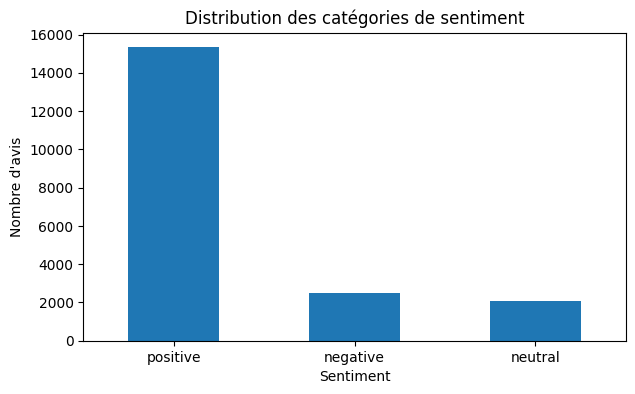

In [14]:
print("Nombre d'avis par sentiment :")
print(df["Sentiment"].value_counts())

print("\nPourcentage par sentiment :")
print((df["Sentiment"].value_counts(normalize=True) * 100).round(2))

df["Sentiment"].value_counts().plot(
    kind="bar",
    figsize=(7, 4)
)

plt.title("Distribution des catégories de sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Nombre d'avis")
plt.xticks(rotation=0)
plt.show()

## 3. Prétraitement des textes

Le prétraitement consiste à nettoyer et normaliser les avis avant leur représentation numérique. Il permet de réduire le bruit dans les données et de faciliter l'analyse automatique des textes.

Les principales opérations appliquées sont la conversion en minuscules, la suppression des URL, de la ponctuation et des caractères inutiles, ainsi que le retrait des mots vides (*stopwords*). Les négations importantes sont conservées, car elles peuvent modifier le sens d'un avis.

— Créer la fonction de nettoyage

In [12]:
import re
import nltk
from nltk.corpus import stopwords

# Télécharger les mots vides anglais
nltk.download("stopwords")

# Charger les stopwords anglais
stop_words = set(stopwords.words("english"))

# Conserver les mots importants pour le sentiment
for word in ["no", "nor", "not"]:
    stop_words.discard(word)

print("Nombre de stopwords :", len(stop_words))
print("Exemples :", list(stop_words)[:10])   


def clean_text(text):
    # 1. Convertir le texte en minuscules
    text = str(text).lower()

    # 2. Supprimer les URL
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)

    # 3. Supprimer les balises HTML
    text = re.sub(r"<.*?>", " ", text)

    # 4. Supprimer les caractères non alphabétiques
    text = re.sub(r"[^a-z\s]", " ", text)

    # 5. Supprimer les espaces multiples
    text = re.sub(r"\s+", " ", text).strip()

    # 6. Supprimer les stopwords
    words = text.split()
    words = [word for word in words if word not in stop_words]

    # 7. Reconstituer le texte nettoyé
    return " ".join(words)


# Appliquer le nettoyage à tous les avis
df["Cleaned Review"] = df["Review Text"].apply(clean_text)

# Comparer les avis originaux et nettoyés
display(df[["Review Text", "Cleaned Review"]].head(10))

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\ABI\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Nombre de stopwords : 195
Exemples : ["you've", 've', 'haven', 'be', 'he', 'few', 'a', 'other', "she'll", 'ours']


,Review Text,Cleaned Review
0,All I can say is they have very good ice cream I would for sure recommend their cookies and creme ice cream it is very good,say good ice cream would sure recommend cookies creme ice cream good
1,Nice little local place for ice cream.My favorite is their pumpkin shake ( Fall season special).( My Sweetness tolerance is low) Their LARGE SIZE ...,nice little local place ice cream favorite pumpkin shake fall season special sweetness tolerance low large size ice cream usually seems sweet ice ...
2,A delicious treat on a hot day! Staff was very friendly and helpful-- gave us a sample and let us order a little earlier than open.,delicious treat hot day staff friendly helpful gave us sample let us order little earlier open
3,This was great service and a fun crew! I got the banana cream pie with chocolate ice cream. I loved the flavor of this. It had freshly cut bananas...,great service fun crew got banana cream pie chocolate ice cream loved flavor freshly cut bananas graham crackers chocolate ice cream yum thing not...
4,"This is one of my favorite places to get ice cream in the CU area. It's a bit of drive, but it is worth it. It's about 10 minutes from the far sid...",one favorite places get ice cream cu area bit drive worth minutes far side urbana getting really easy atmosphere dairy barn kid friendly many tabl...
5,"I've been coming to this ice cream stand since I was a little girl back in the 1970's. (Yes, it's been here for that long! Just not under the same...",coming ice cream stand since little girl back yes long not ownership not much changed years regards basic ice cream great family place always acco...
6,"The soft-serve is way too sweet and has a strange Splenda-like aftertaste. The flavors tasted very artificial, and I ended up with a stomach ache ...",soft serve way sweet strange splenda like aftertaste flavors tasted artificial ended stomach ache got home really recommend place simple baskin ro...
7,My husband and I stopped here on the way back to Monticello from Westville (Go Sages!). He had a chocolate shake and I had a cookie dough tornado....,husband stopped way back monticello westville go sages chocolate shake cookie dough tornado tasty refreshing cute place filled character service f...
8,"Little piece of heaven, the best ice cream shop near Champaign Urbana. Decent prices, superb taste; What else do you need on a hot summer day! Thi...",little piece heaven best ice cream shop near champaign urbana decent prices superb taste else need hot summer day place cash sometimes smell cow d...
9,Went here for the 1st time tonight. I ordered a turtle tornado. It was excellent. TONS of pecans and lots of flavor. I guess I could be picky and ...,went st time tonight ordered turtle tornado excellent tons pecans lots flavor guess could picky say melted incredibly fast bad wife son experience...


— Appliquer le nettoyage

### 3.2 — Tokenisation

In [13]:
from nltk.tokenize import word_tokenize
print(word_tokenize("I didn't like it, but the staff was great!"))
df["tokens"] = df["Cleaned Review"].apply(word_tokenize)

['I', 'did', "n't", 'like', 'it', ',', 'but', 'the', 'staff', 'was', 'great', '!']


### 3.3 — Correction orthographique

In [14]:
%pip install pyspellchecker
from spellchecker import SpellChecker
from collections import Counter
from functools import lru_cache

spell = SpellChecker(); spell.distance = 1 #  correction dans une seule modification 
freq = Counter(w for t in df["tokens"] for w in t)

@lru_cache(maxsize=None) #mémorise les résultats, donc un mot déjà corrigé n’est pas recalculé
def fix(w):
    if freq[w] >= 5 or len(w) <= 3:      # mot fréquent ou très court : on n'y touche pas
        return w
    return spell.correction(w) or w

df["tokens_fixed"] = df["tokens"].apply(lambda ts: [fix(w) for w in ts])

n = sum(a != b for x, y in zip(df["tokens"], df["tokens_fixed"]) for a, b in zip(x, y))
print("Mots corrigés :", n)

   ---------------------------------------- 0.0/7.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/7.2 MB ? eta -:--:--
   ---- ----------------------------------- 0.8/7.2 MB 3.8 MB/s eta 0:00:02
   ----------- ---------------------------- 2.1/7.2 MB 5.3 MB/s eta 0:00:01
   -------------------- ------------------- 3.7/7.2 MB 5.9 MB/s eta 0:00:01
   ------------------------------ --------- 5.5/7.2 MB 6.8 MB/s eta 0:00:01
   ---------------------------------------- 7.2/7.2 MB 7.2 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.
Mots corrigés : 2781


### 3.4 —  POS tagging, stemming et lemmatisation

In [16]:
from nltk import pos_tag
from nltk.corpus import wordnet
from nltk.stem import PorterStemmer, WordNetLemmatizer

print(pos_tag(df["tokens_fixed"].iloc[0])[:10])      # démonstration du POS tagging

def wn_pos(tag):
    return {"J": wordnet.ADJ, "V": wordnet.VERB, "R": wordnet.ADV}.get(tag[0], wordnet.NOUN)

stemmer, lemmatizer = PorterStemmer(), WordNetLemmatizer()
def lemmatize(tokens):
    return [lemmatizer.lemmatize(w, wn_pos(t)) for w, t in pos_tag(tokens)]

df["Corrected"]  = df["tokens_fixed"].apply(" ".join)
df["Stemmed"]    = df["tokens_fixed"].apply(lambda ts: " ".join(stemmer.stem(w) for w in ts))
df["Lemmatized"] = df["tokens_fixed"].apply(lambda ts: " ".join(lemmatize(ts)))
df[["Cleaned Review", "Stemmed", "Lemmatized"]].head(5)

[('say', 'VB'), ('good', 'JJ'), ('ice', 'NN'), ('cream', 'NN'), ('would', 'MD'), ('sure', 'VB'), ('recommend', 'VB'), ('cookies', 'NNS'), ('creme', 'JJ'), ('ice', 'NN')]


,Cleaned Review,Stemmed,Lemmatized
0,say good ice cream would sure recommend cookies creme ice cream good,say good ice cream would sure recommend cooki creme ice cream good,say good ice cream would sure recommend cooky creme ice cream good
1,nice little local place ice cream favorite pumpkin shake fall season special sweetness tolerance low large size ice cream usually seems sweet ice ...,nice littl local place ice cream favorit pumpkin shake fall season special sweet toler low larg size ice cream usual seem sweet ice cream love pin...,nice little local place ice cream favorite pumpkin shake fall season special sweetness tolerance low large size ice cream usually seem sweet ice c...
2,delicious treat hot day staff friendly helpful gave us sample let us order little earlier open,delici treat hot day staff friendli help gave us sampl let us order littl earlier open,delicious treat hot day staff friendly helpful give u sample let u order little earlier open
3,great service fun crew got banana cream pie chocolate ice cream loved flavor freshly cut bananas graham crackers chocolate ice cream yum thing not...,great servic fun crew got banana cream pie chocol ice cream love flavor freshli cut banana graham cracker chocol ice cream yum thing notic melt pr...,great service fun crew get banana cream pie chocolate ice cream love flavor freshly cut bananas graham cracker chocolate ice cream yum thing notic...
4,one favorite places get ice cream cu area bit drive worth minutes far side urbana getting really easy atmosphere dairy barn kid friendly many tabl...,one favorit place get ice cream cu area bit drive worth minut far side urbana get realli easi atmospher dairi barn kid friendli mani tabl set sit ...,one favorite place get ice cream cu area bit drive worth minute far side urbana get really easy atmosphere dairy barn kid friendly many table set ...


## 4. Représentation numérique des textes

Les algorithmes de classification nécessitent des données numériques. Nous utilisons donc deux techniques de représentation textuelle : Bag of Words (CountVectorizer) et TF-IDF (TfidfVectorizer).

Bag of Words représente les textes à partir des fréquences des mots, tandis que TF-IDF pondère les mots en fonction de leur importance dans un document par rapport à l'ensemble du corpus.

Préparer les données

In [17]:
from sklearn.model_selection import train_test_split

# Textes et étiquettes
X = df["Cleaned Review"]
y = df["Sentiment"]

# Séparation : 80 % entraînement, 20 % test
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Taille des données d'entraînement :", len(X_train))
print("Taille des données de test :", len(X_test))

print("\nRépartition des classes dans l'entraînement :")
print(y_train.value_counts())

print("\nRépartition des classes dans le test :")
print(y_test.value_counts())

Taille des données d'entraînement : 15916
Taille des données de test : 3980

Répartition des classes dans l'entraînement :
Sentiment
positive    12263
negative     1998
neutral      1655
Name: count, dtype: int64

Répartition des classes dans le test :
Sentiment
positive    3067
negative     499
neutral      414
Name: count, dtype: int64


### 4.1 — Rééquilibrage des classes par suréchantillonnage (RandomOverSampler)

In [18]:
from imblearn.over_sampling import RandomOverSampler
import pandas as pd

# Vérifier la distribution avant le rééquilibrage
print("Avant le rééquilibrage :")
print(y_train.value_counts())

# Créer le rééquilibreur
ros = RandomOverSampler(random_state=42)

# Rééquilibrer uniquement les données d'entraînement
X_train_balanced, y_train_balanced = ros.fit_resample(
    X_train.to_frame(name="Review Text"),
    y_train
)

# Reconvertir les textes en Series pandas
X_train_balanced = X_train_balanced["Review Text"]

# Vérifier la distribution après le rééquilibrage
print("\nAprès le rééquilibrage :")
print(y_train_balanced.value_counts())

print("\nDimensions après rééquilibrage :")
print("X_train :", X_train_balanced.shape)
print("y_train :", y_train_balanced.shape)

print("\nDistribution du test (inchangée) :")
print(y_test.value_counts())

Avant le rééquilibrage :
Sentiment
positive    12263
negative     1998
neutral      1655
Name: count, dtype: int64

Après le rééquilibrage :
Sentiment
positive    12263
neutral     12263
negative    12263
Name: count, dtype: int64

Dimensions après rééquilibrage :
X_train : (36789,)
y_train : (36789,)

Distribution du test (inchangée) :
Sentiment
positive    3067
negative     499
neutral      414
Name: count, dtype: int64


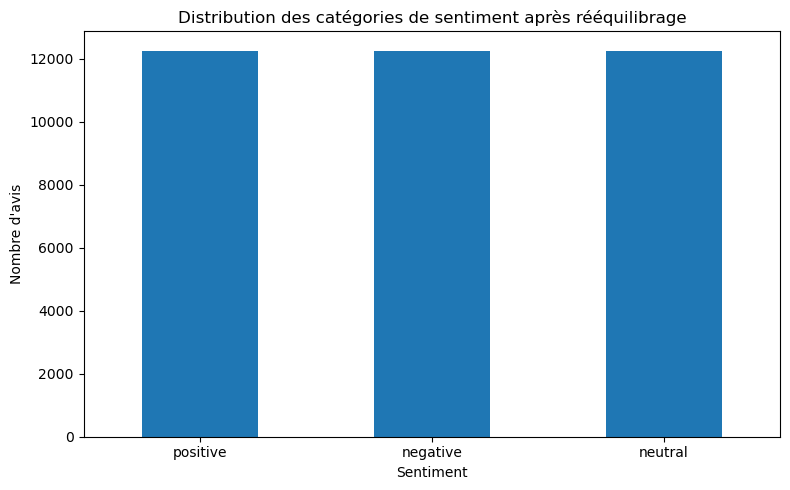

In [19]:
import matplotlib.pyplot as plt

# Distribution des sentiments après rééquilibrage
plt.figure(figsize=(8, 5))

y_train_balanced.value_counts().reindex(
    ["positive", "negative", "neutral"]
).plot(kind="bar")

plt.title("Distribution des catégories de sentiment après rééquilibrage")
plt.xlabel("Sentiment")
plt.ylabel("Nombre d'avis")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

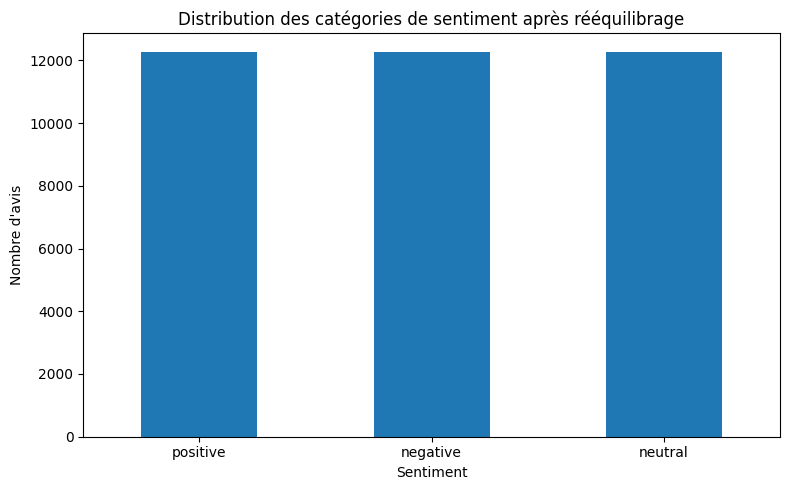

In [24]:
import matplotlib.pyplot as plt

# Distribution des sentiments après rééquilibrage
plt.figure(figsize=(8, 5))

y_train_balanced.value_counts().reindex(
    ["positive", "negative", "neutral"]
).plot(kind="bar")

plt.title("Distribution des catégories de sentiment après rééquilibrage")
plt.xlabel("Sentiment")
plt.ylabel("Nombre d'avis")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Appliquer Bag of Words et TF-IDF

### 5 — Représentation numérique : Bag of Words et TF-IDF

In [20]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

# Bag of Words
bow_vectorizer = CountVectorizer(max_features=20000) ##garde les 20 000 mots les plus fréquents

X_train_bow = bow_vectorizer.fit_transform(X_train_balanced)
X_test_bow = bow_vectorizer.transform(X_test)

# TF-IDF
tfidf_vectorizer = TfidfVectorizer(max_features=20000)

X_train_tfidf = tfidf_vectorizer.fit_transform(X_train_balanced)
X_test_tfidf = tfidf_vectorizer.transform(X_test)

print("Dimensions BoW :", X_train_bow.shape)
print("Dimensions TF-IDF :", X_train_tfidf.shape)

Dimensions BoW : (36789, 19605)
Dimensions TF-IDF : (36789, 19605)




**1. Bag of Words (sac de mots)**
- **Principe :** chaque avis est représenté par le **nombre d'occurrences** de chaque mot du vocabulaire.
- **Avantage :** simple et rapide.
- **Limite :** tous les mots ont le même poids, donc des mots très fréquents mais peu informatifs (`food`, `place`) dominent. L'ordre des mots est ignoré.

**2. TF-IDF (Term Frequency – Inverse Document Frequency)**
- **Principe :** un mot a un poids élevé s'il est **fréquent dans un avis** mais **rare dans l'ensemble du corpus**.
- **Avantage :** il met en valeur les mots discriminants (`rude`, `delicious`, `terrible`) et réduit l'importance des mots courants.
- **Limite :** l'ordre des mots et le contexte restent ignorés.



### 5.1 Observer la représentation numérique

In [21]:
# Afficher quelques mots du vocabulaire BoW
print("Exemples de mots du vocabulaire :")
print(list(bow_vectorizer.vocabulary_.keys())[:20])

# Afficher la représentation du premier avis d'entraînement
print("\nReprésentation BoW du premier avis :")
print(X_train_bow[0])

print("\nReprésentation TF-IDF du premier avis :")
print(X_train_tfidf[0])

Exemples de mots du vocabulaire :
['quaint', 'cute', 'ice', 'cream', 'candy', 'shop', 'make', 'homemade', 'sorbet', 'tasted', 'amazing', 'tried', 'vegan', 'coconut', 'absolutely', 'loved', 'usually', 'eat', 'good', 'lots']

Représentation BoW du premier avis :
<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 19 stored elements and shape (1, 19605)>
  Coords	Values
  (0, 13690)	1
  (0, 4323)	1
  (0, 8632)	2
  (0, 4018)	2
  (0, 2453)	1
  (0, 15461)	1
  (0, 10425)	1
  (0, 8384)	1
  (0, 16088)	2
  (0, 17194)	1
  (0, 531)	1
  (0, 17916)	1
  (0, 18570)	2
  (0, 3291)	1
  (0, 50)	1
  (0, 10240)	1
  (0, 18473)	1
  (0, 5592)	1
  (0, 7594)	1

Représentation TF-IDF du premier avis :
<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 19 stored elements and shape (1, 19605)>
  Coords	Values
  (0, 13690)	0.29081343472812654
  (0, 4323)	0.1690427171377382
  (0, 8632)	0.18744599777215948
  (0, 4018)	0.17363577912073916
  (0, 2453)	0.23035305019225125
  (0, 15461)	0.155927956425981

### 6 — Entraîner les modèles de classification

In [22]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

import pandas as pd

models = {
    "Naive Bayes": MultinomialNB(),

    "Logistic Regression": LogisticRegression(
        max_iter=1000,

        random_state=42
    ),

    "Linear SVM": LinearSVC(
    
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

results = []
trained_models = {}

for name, model in models.items():
    print(f"\n{'=' * 50}")
    print(f"Entraînement du modèle : {name}")
    print(f"{'=' * 50}")

    model.fit(X_train_tfidf, y_train_balanced)
    y_pred = model.predict(X_test_tfidf)

    trained_models[name] = model

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision macro": precision_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Recall macro": recall_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "F1 macro": f1_score(
            y_test, y_pred, average="macro", zero_division=0
        )
    })

    print(classification_report(y_test, y_pred, zero_division=0))

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1 macro", ascending=False
).reset_index(drop=True)

display(results_df.round(4))


Entraînement du modèle : Naive Bayes
              precision    recall  f1-score   support

    negative       0.62      0.68      0.65       499
     neutral       0.31      0.58      0.40       414
    positive       0.96      0.83      0.89      3067

    accuracy                           0.78      3980
   macro avg       0.63      0.70      0.65      3980
weighted avg       0.85      0.78      0.81      3980


Entraînement du modèle : Logistic Regression
              precision    recall  f1-score   support

    negative       0.65      0.73      0.69       499
     neutral       0.40      0.54      0.45       414
    positive       0.95      0.89      0.92      3067

    accuracy                           0.83      3980
   macro avg       0.67      0.72      0.69      3980
weighted avg       0.86      0.83      0.84      3980


Entraînement du modèle : Linear SVM
              precision    recall  f1-score   support

    negative       0.65      0.67      0.66       499
     neu

,Model,Accuracy,Precision macro,Recall macro,F1 macro
0,Logistic Regression,0.8329,0.6671,0.7174,0.6876
1,Linear SVM,0.8284,0.6509,0.6702,0.6597
2,Naive Bayes,0.7844,0.6289,0.6972,0.6470
3,Random Forest,0.8249,0.7542,0.4926,0.5113



**Analyse par modèle :**
- **Régression logistique : meilleur modèle** (F1 macro = 0.69, recall macro = 0.73). C'est celui qui reconnaît le mieux les classes minoritaires (négatif et neutre). Il convient bien aux données textuelles de grande dimension (TF-IDF).
- **Linear SVM :** meilleure accuracy (0.8475) mais F1 macro un peu plus faible (0.67). Il est très performant globalement, mais moins équilibré entre les classes que la régression logistique.
- **Random Forest :** accuracy correcte (0.80) mais recall macro faible (0.42). Il est biaisé vers la classe majoritaire, et les arbres sont peu adaptés aux matrices TF-IDF creuses de ~20 000 dimensions.
- **Naive Bayes :** le plus faible (F1 macro = 0.31). Il prédit presque tout en « positive » (accuracy 0.77, soit le niveau du modèle qui prédit toujours « positive »), donc il n'apprend pratiquement pas les classes négative et neutre.

**Conclusion :** la régression logistique est retenue, car elle offre le meilleur compromis entre les trois classes. Le classement des modèles dépend de la métrique choisie (accuracy : SVM ; F1 macro : régression logistique), ce qui justifie le choix du F1 macro dans un contexte déséquilibré.

In [28]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1 macro",
    ascending=False
).reset_index(drop=True)

results_df

,Model,Accuracy,Precision macro,Recall macro,F1 macro
0,Logistic Regression,0.828392,0.665360,0.730352,0.690434
1,Linear SVM,0.847487,0.672725,0.672405,0.671804
2,Naive Bayes,0.773116,0.507736,0.341132,0.306152


Visualiser le F1 macro

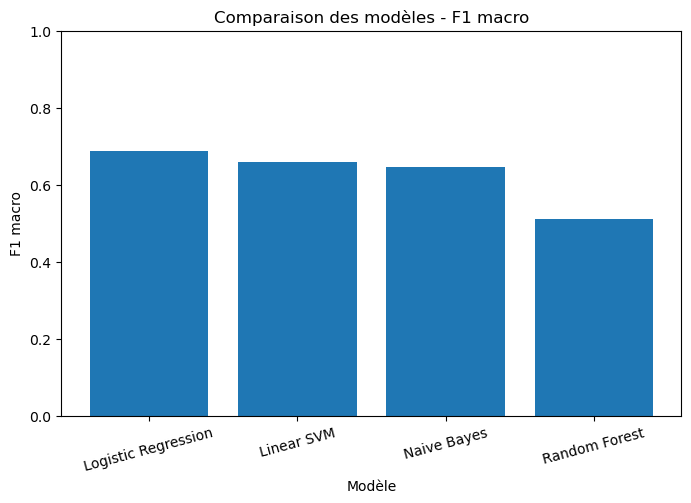

In [23]:
plt.figure(figsize=(8, 5))

plt.bar(results_df["Model"], results_df["F1 macro"])

plt.title("Comparaison des modèles - F1 macro")
plt.xlabel("Modèle")
plt.ylabel("F1 macro")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.show()

Meilleur modèle : Logistic Regression


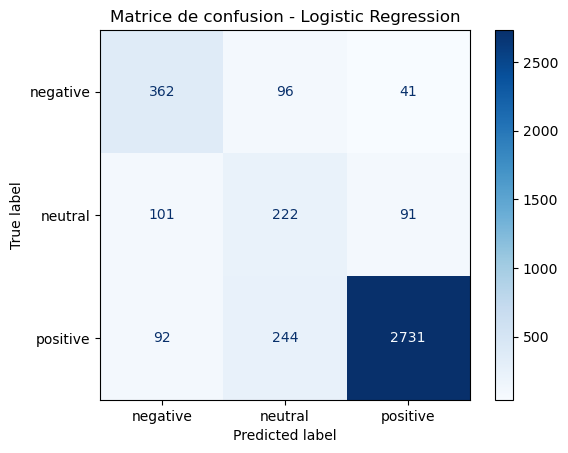

In [24]:
from sklearn.metrics import ConfusionMatrixDisplay

best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

y_pred_best = best_model.predict(X_test_tfidf)

print("Meilleur modèle :", best_model_name)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_best,
    labels=["negative", "neutral", "positive"],
    cmap="Blues",
    values_format="d"
)

plt.title(f"Matrice de confusion - {best_model_name}")
plt.show()

In [25]:
def predict_sentiment(text):
    """Applique le même prétraitement que l'entraînement, puis prédit la polarité."""
    cleaned = clean_text(text)
    vect = tfidf_vectorizer.transform([cleaned])
    label = best_model.predict(vect)[0]

    print("Avis original :", text)
    print("Avis nettoyé  :", cleaned)
    print("Prédiction    :", label.upper())

    # Probabilités par classe (la régression logistique les fournit, pas LinearSVC)
    if hasattr(best_model, "predict_proba"):
        for cls, p in zip(best_model.classes_, best_model.predict_proba(vect)[0]):
            print(f"   {cls:<9} {p:.1%}")
    print("-" * 50)

# Tests prédéfinis
tests = [
    "Amazing food and great service, I will definitely come back!",
    "The food wasn't good and the staff was rude.",
    "It was okay, nothing special.",
    "Good pizza but the service was very slow."
]
for t in tests:
    predict_sentiment(t)

# Test avec ton propre avis (saisie au clavier)
predict_sentiment(input("Écris un avis en anglais : "))

Avis original : Amazing food and great service, I will definitely come back!
Avis nettoyé  : amazing food great service definitely come back
Prédiction    : POSITIVE
   negative  0.0%
   neutral   1.9%
   positive  98.1%
--------------------------------------------------
Avis original : The food wasn't good and the staff was rude.
Avis nettoyé  : food good staff rude
Prédiction    : NEUTRAL
   negative  46.3%
   neutral   51.8%
   positive  1.9%
--------------------------------------------------
Avis original : It was okay, nothing special.
Avis nettoyé  : okay nothing special
Prédiction    : NEUTRAL
   negative  31.4%
   neutral   68.5%
   positive  0.1%
--------------------------------------------------
Avis original : Good pizza but the service was very slow.
Avis nettoyé  : good pizza service slow
Prédiction    : NEGATIVE
   negative  70.4%
   neutral   7.4%
   positive  22.2%
--------------------------------------------------


Écris un avis en anglais :  hello ,i hope this message find you well


Avis original : hello ,i hope this message find you well
Avis nettoyé  : hello hope message find well
Prédiction    : POSITIVE
   negative  18.6%
   neutral   11.2%
   positive  70.1%
--------------------------------------------------


In [27]:
import joblib

joblib.dump(
    trained_models["Logistic Regression"],
    "logistic_regression.joblib"
)

joblib.dump(
    tfidf_vectorizer,
    "tfidf_vectorizer.joblib"
)

joblib.dump(stop_words, "stop_words.joblib")

print("Modèle et vectoriseur sauvegardés avec succès !")

Modèle et vectoriseur sauvegardés avec succès !
